# **Blinkit Sales & Marketing Analysis**

## Overview
This project analyzes a retail dataset from Blinkit to understand how product and outlet characteristics relate to sales. It follows the standard analyst workflow: load and clean the data, explore it, then answer a set of business questions, checking each result for hidden explanations before drawing a conclusion.

## Objective
To identify which factors (outlet characteristics, product attributes, visibility, rating) actually relate to sales performance, and to turn the findings into insights for marketing and sales teams.

## Dataset
- **8,523 rows x 12 columns.**
- Each row is **one product sold at one specific outlet** (an item-outlet combination). The same product appears in several rows, once per outlet that sells it.
- Columns by role:
  - *Product:* `Item Identifier`, `Item Type`, `Item Fat Content`, `Item Weight`, `Item Visibility`, `Rating`
  - *Outlet:* `Outlet Identifier`, `Outlet Establishment Year`, `Outlet Size`, `Outlet Location Type`, `Outlet Type`
  - *Outcome:* `Sales`

## Important Dataset Notes
Three limits of this dataset shape what we can and cannot conclude:
1. **It is a snapshot, not a time series.** There is no sale date. `Outlet Establishment Year` is when the outlet opened, not when a sale happened, so trends over time cannot be analyzed.
2. **`Sales` is a value (revenue), not units sold.** A high Sales figure can mean a high price rather than high demand.
3. **There is no customer-level data.** The data shows what outlets stock and sell, not what individual customers choose.

## Key Questions
**Category 1: Outlet-Level Analysis**
1. Does the outlet establishment year affect sales?
2. Which outlet and location generates the highest sales?
3. What products sell best at each outlet type and location?

**Category 2: Product-Level Analysis**

4. Which product type sells the most overall?
5. Do customers prefer Low Fat or Regular products?

**Category 3: Driver & Root-Cause Analysis**

6. Does higher product visibility drive higher sales, or does it depend on product type?
7. Which products underperform, and why (rating, fat content, or product type)?
8. Is a higher rating associated with higher sales, or is it driven by outlet location?
9. Does product weight influence sales, or is it driven by product type?

## Workflow
1. Setup (libraries, load data)
2. Data cleaning
3. Exploratory data analysis (EDA)
4. Business analysis (Questions 1-9)
5. Summary, limitations and recommendations

## Tools Used
Python (pandas, Matplotlib)

## **1. Setup**
### Import libraries
- **pandas**: loads and manipulates the data (a table is called a *DataFrame*, `df`).
- **matplotlib**: draws the charts.
- seaborn is imported but not used in this notebook.

The first cell installs the libraries and only needs to be run once.

In [58]:
%pip install pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load the dataset
`pd.read_csv` reads the CSV file into a DataFrame called `df`. `df.head()` shows the first five rows, a quick check that the file loaded correctly and the columns look as expected.

In [60]:
df =  pd.read_csv('blinkit_data.csv')
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## **2. Data Cleaning**
**Goal:** before analyzing anything, check the data for missing values, duplicate rows and wrong data types. Conclusions built on dirty data can be wrong without any error message.

In [61]:
# check info of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


**What `df.info()` shows**
- Every column has 8,523 non-null values **except `Item Weight`**, which has 7,060.
- So `Item Weight` has 8,523 - 7,060 = **1,463 missing values**.
- Data types look right: text columns are `object`, numeric columns are `int64` / `float64`.

In [62]:
# Check missing values (NULL)
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

`df.isnull().sum()` confirms it: `Item Weight` has **1,463** missing values and every other column has **0**.

In [63]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

### Handling the 1,463 missing values in `Item Weight`
**Decision: do not drop the rows.** 1,463 of 8,523 rows (~17%) is a large share. Dropping them would throw away valid information in the other columns and could bias the analysis.

**First approach (used in the cell below): fill with the column mean.** Replacing each missing weight with the average weight (~12.86) is a quick, reasonable placeholder.

> **Update (see Question 9):** later we investigated *why* the weights were missing and found a better method. All missing values came from just two outlets, and every product has the same weight in every outlet, so the real weight can be copied from the same product in another outlet. The mean-filled values are replaced with these in Question 9. Questions 1-8 do not use `Item Weight`, so none of their results are affected.

**Lesson:** before filling in missing data, ask *why* it is missing. A systematic pattern (two outlets that never recorded weight) calls for a different fix than random gaps.

In [64]:
df['Item Weight'] = df['Item Weight'].fillna(df['Item Weight'].mean())

In [65]:
df.isnull().sum()

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64

Verification: no missing values remain (for now).

## **3. Exploratory Data Analysis (EDA)**
**Goal:** get to know the data (ranges, categories, unusual values) before asking business questions.

In [66]:
# Summary statistics for numeric column
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.857645,140.992782,3.965857
std,8.371760,0.051598,4.226124,62.275067,0.605651
min,1998.000000,0.000000,4.555000,31.290000,1.000000
25%,2000.000000,0.026989,9.310000,93.826500,4.000000
50%,2012.000000,0.053931,12.857645,143.012800,4.000000
75%,2017.000000,0.094585,16.000000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


**What `describe()` tells us**
- `Outlet Establishment Year` ranges from 1998 to 2022.
- `Item Visibility` has a **minimum of 0.000**, which is implausible for a product that is on sale. Handled in Question 6.
- `Rating` runs from 1 to 5, with the 25th, 50th and 75th percentiles at 4.0, 4.0 and 4.2, a hint that ratings cluster around 4. Explored in Question 8.
- `Sales` has a mean of ~141 and a standard deviation of ~62.
- `Item Weight` has identical mean and median (12.857645). That is an artifact of filling 1,463 rows with the mean, not a real property of the data.

In [67]:
# Unique values for category column
print(df['Item Fat Content'].unique())
print(df['Outlet Size'].unique())
print(df['Outlet Location Type'].unique())
print(df['Outlet Type'].unique())
print(df['Item Type'].unique())


['Regular' 'Low Fat' 'low fat' 'LF' 'reg']
['Medium' 'Small' 'High']
['Tier 1' 'Tier 3' 'Tier 2']
['Supermarket Type1' 'Supermarket Type2' 'Grocery Store'
 'Supermarket Type3']
['Fruits and Vegetables' 'Health and Hygiene' 'Frozen Foods' 'Canned'
 'Soft Drinks' 'Household' 'Snack Foods' 'Meat' 'Breads' 'Hard Drinks'
 'Others' 'Dairy' 'Breakfast' 'Baking Goods' 'Seafood' 'Starchy Foods']


The outlet and product categories look consistent, but `Item Fat Content` has five labels. The counts below show the problem.

In [68]:
# Count each category
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

**Problem found: inconsistent labels in `Item Fat Content`**

Five labels describe only two real categories:
- `Low Fat`, `LF`, `low fat` mean **Low Fat**
- `Regular`, `reg` mean **Regular**

Left as is, Python treats them as five different categories and splits the counts, which would give wrong answers for the Low Fat vs Regular question (Question 5). The cell below standardizes them.

In [69]:
# Stamdardize Item Fat Content
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

In [70]:
# Verify the column
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Verified: only two categories remain, **Low Fat (5,517)** and **Regular (3,006)**. The counts add up (5,089 + 316 + 112 = 5,517 and 2,889 + 117 = 3,006).

## **4. Business Analysis**
Each question follows the same pattern: **approach** (and why), **result**, **insight**, **conclusion** with caveats.

**Three ways to summarize a group, and why we use all three**
- **sum** = total. Affected by how many rows the group has.
- **mean** = typical value per row. Fair for comparing groups of different sizes.
- **count** = number of rows.

A group can have a high *sum* simply because it has more rows. Throughout this notebook we check `mean` and `count` next to `sum` before concluding that one group "performs better".

### **Category 1: Outlet-Level Analysis**

#### **Question 1: Does the outlet establishment year affect sales?**
**Approach:** group the rows by establishment year and compare the **average** sales per row. The mean (not the sum) is used so that years with more rows are not unfairly favored. A bar chart is used because the nine years are distinct categories, not a continuous timeline.

In [71]:
sales_by_year = df.groupby('Outlet Establishment Year')['Sales'].mean().sort_index()
print(sales_by_year)

Outlet Establishment Year
1998    139.796485
2000    141.425982
2010    142.057387
2011    140.777594
2012    140.297699
2015    140.950246
2017    143.122481
2020    139.421119
2022    141.678634
Name: Sales, dtype: float64


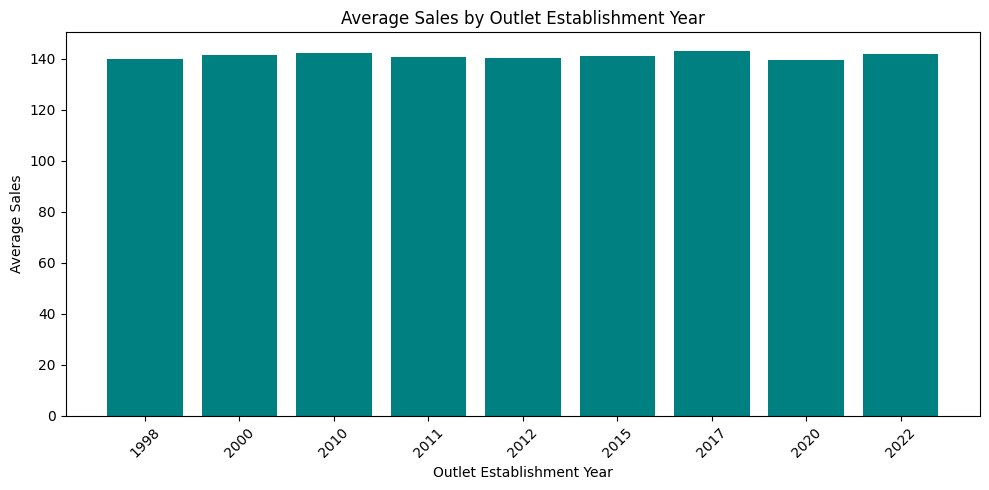

In [72]:
plt.figure(figsize=(10,5))
plt.bar(sales_by_year.index.astype(str), sales_by_year.values, color='teal')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Average Sales')
plt.title('Average Sales by Outlet Establishment Year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight**
- Average sales are almost identical for every establishment year, ranging only from ~RM139.4 (2020) to ~RM143.1 (2017). That spread is under 3% of the overall average (~RM141).
- Old outlets (1998) and new outlets (2022) perform the same.

**Conclusion:** outlet age is not associated with sales in this dataset.

> **Caveat:** this does not prove that outlet age never matters. Question 7 shows that `Sales` behaves almost like a fixed property of each product, so differences between outlets are barely visible in this data. The result says the dataset cannot detect an age effect.

#### **Question 2: Which outlet and location generate the highest sales?**
**Part A: by outlet (total sales).** We start with the **sum** because the question asks where sales are highest overall.

In [73]:
sales_by_outlet = df.groupby('Outlet Identifier')['Sales'].sum().sort_values(ascending=False)
print(sales_by_outlet)

Outlet Identifier
OUT035    133103.9070
OUT046    132113.3698
OUT013    131809.0156
OUT018    131477.7724
OUT045    130942.7782
OUT027    130714.6746
OUT049    130476.8598
OUT017    129103.9564
OUT010     78131.5646
OUT019     73807.5824
Name: Sales, dtype: float64


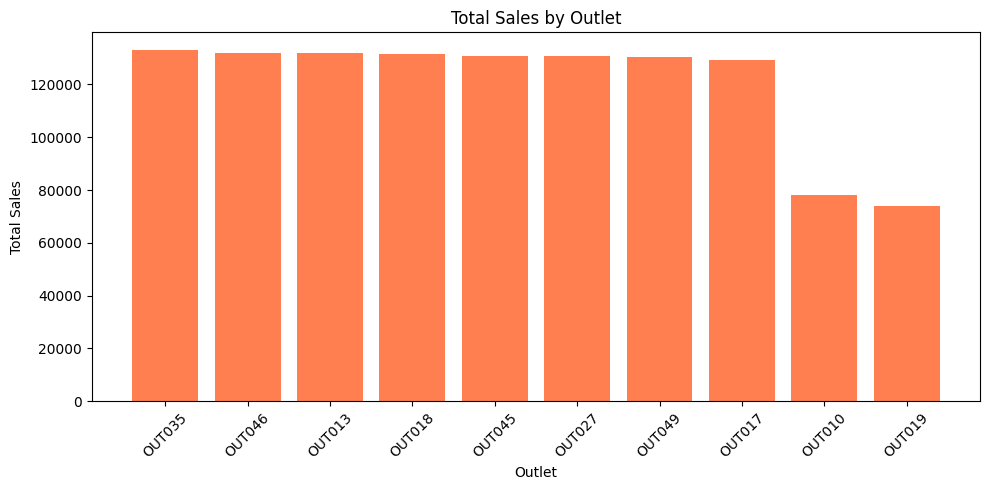

In [74]:
#Visualize (Part A)

plt.figure(figsize=(10,5))
plt.bar(sales_by_outlet.index, sales_by_outlet.values, color='coral')
plt.xlabel('Outlet')
plt.ylabel('Total Sales')
plt.title('Total Sales by Outlet')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight (by outlet)**
- Eight outlets (OUT035 to OUT017) have similar totals of ~RM129K-133K.
- Two outlets, **OUT010 (~RM78K)** and **OUT019 (~RM74K)**, are far lower, roughly 40% below the others.

**Red flag:** why do these two lag? Possible explanations to test: outlet size, outlet type, location tier.

**Part B: by location tier (total sales).**

In [75]:
sales_by_location = df.groupby('Outlet Location Type')['Sales'].sum().sort_values(ascending=False)
print(sales_by_location)

Outlet Location Type
Tier 3    472133.0272
Tier 2    393150.6416
Tier 1    336397.8120
Name: Sales, dtype: float64


Tier 3 has the highest total, but a total can be misleading. The next cell adds `mean` and `count` for a fair comparison.

In [76]:
df.groupby('Outlet Location Type')['Sales'].agg(['sum', 'mean', 'count'])

,sum,mean,count
Outlet Location Type,,,
Tier 1,336397.8120,140.870106,2388
Tier 2,393150.6416,141.167196,2785
Tier 3,472133.0272,140.935232,3350


**Insight (by location tier)**

| Tier | Total sales | Mean per row | Rows |
|---|---|---|---|
| Tier 1 | 336,398 | 140.87 | 2,388 |
| Tier 2 | 393,151 | 141.17 | 2,785 |
| Tier 3 | 472,133 | 140.94 | 3,350 |

- The **mean is ~RM141 in all three tiers.** Products sell equally well per row everywhere.
- Tier 3 has the highest total only because it has **more rows** (3,350 vs 2,388 in Tier 1).

This is a **confounding variable** at work: the number of rows drives the total, not better per-product performance.

**Investigating the two low outlets (OUT010, OUT019)**

The next cell lists their outlet type, size and tier.

In [77]:
df[df['Outlet Identifier'].isin(['OUT010', 'OUT019'])][['Outlet Identifier', 'Outlet Type', 'Outlet Size', 'Outlet Location Type']].drop_duplicates()

,Outlet Identifier,Outlet Type,Outlet Size,Outlet Location Type
6,OUT010,Grocery Store,Small,Tier 3
44,OUT010,Grocery Store,Medium,Tier 3
91,OUT019,Grocery Store,Small,Tier 1
304,OUT010,Grocery Store,High,Tier 3


**Data quality problem found:** OUT010 appears three times with three different `Outlet Size` values (Small, Medium, High). A single outlet cannot have three sizes, so `Outlet Size` is inconsistent in the source data. Counting the rows per size for OUT010:

In [78]:
df[df['Outlet Identifier']=='OUT010']['Outlet Size'].value_counts()

Outlet Size
Medium    265
High      233
Small      57
Name: count, dtype: int64

Now check which outlets are affected. `nunique()` counts how many different sizes each outlet has; a consistent outlet should show 1.

In [79]:
df.groupby('Outlet Identifier')['Outlet Size'].nunique()

Outlet Identifier
OUT010    3
OUT013    1
OUT017    3
OUT018    1
OUT019    1
OUT027    1
OUT035    1
OUT045    3
OUT046    1
OUT049    1
Name: Outlet Size, dtype: int64

Three outlets are affected: **OUT010, OUT017 and OUT045** (3 different sizes each). The other seven are consistent.

**Fix:** assign each outlet its most frequent size (the *mode*).

In [80]:
outlet_size_mode = df.groupby('Outlet Identifier')['Outlet Size'].agg(lambda x: x.mode()[0])
print(outlet_size_mode)

Outlet Identifier
OUT010    Medium
OUT013      High
OUT017     Small
OUT018    Medium
OUT019     Small
OUT027    Medium
OUT035     Small
OUT045    Medium
OUT046     Small
OUT049    Medium
Name: Outlet Size, dtype: object


In [81]:
df['Outlet Size'] = df['Outlet Identifier'].map(outlet_size_mode)

In [82]:
df.groupby('Outlet Identifier')['Outlet Size'].nunique()


Outlet Identifier
OUT010    1
OUT013    1
OUT017    1
OUT018    1
OUT019    1
OUT027    1
OUT035    1
OUT045    1
OUT046    1
OUT049    1
Name: Outlet Size, dtype: int64

Every outlet now has exactly one size.

> **Caveat:** the mode is a pragmatic choice, not a verified fact. The split is close: for OUT010 it is Medium 265, High 233, Small 57, and there is no clear majority for OUT017 and OUT045 either. `Outlet Size` should be treated as **unreliable for OUT010, OUT017 and OUT045**. It is not used to support any conclusion in this notebook.

After the fix, the two low outlets:

In [83]:
df[df['Outlet Identifier'].isin(['OUT010', 'OUT019'])][['Outlet Identifier', 'Outlet Type', 'Outlet Size', 'Outlet Location Type']].drop_duplicates()

,Outlet Identifier,Outlet Type,Outlet Size,Outlet Location Type
6,OUT010,Grocery Store,Medium,Tier 3
91,OUT019,Grocery Store,Small,Tier 1


Both OUT010 and OUT019 are **Grocery Stores**. They differ in size (Medium vs Small) and in tier (Tier 3 vs Tier 1), so the shared factor is the **outlet type**, not size or tier. The next cell tests this across all outlet types.


In [84]:
df.groupby('Outlet Type')['Sales'].agg(['sum', 'mean', 'count']).sort_values('mean', ascending=False)

,sum,mean,count
Outlet Type,,,
Supermarket Type2,131477.7724,141.678634,928
Supermarket Type1,787549.8868,141.213894,5577
Grocery Store,151939.1470,140.294688,1083
Supermarket Type3,130714.6746,139.801791,935


**Insight (by outlet type)**
- Mean sales per row are ~RM140-142 for **all four types**. Grocery Stores do not sell worse per product.
- The row counts differ a lot: Supermarket Type1 has 5,577 rows vs 1,083 for Grocery Stores. (Type1 also covers six outlets, while Grocery Store covers two.)

**Check: do outlet totals simply follow the number of products listed?** The next cell compares each outlet's total with its row count.

In [85]:
outlet_check = df.groupby('Outlet Identifier')['Sales'].agg(['sum', 'mean', 'count'])
print(outlet_check)
print(outlet_check['sum'].corr(outlet_check['count']))

                           sum        mean  count
Outlet Identifier                                
OUT010              78131.5646  140.777594    555
OUT013             131809.0156  141.425982    932
OUT017             129103.9564  139.421119    926
OUT018             131477.7724  141.678634    928
OUT019              73807.5824  139.787088    528
OUT027             130714.6746  139.801791    935
OUT035             133103.9070  143.122481    930
OUT045             130942.7782  140.950246    929
OUT046             132113.3698  142.057387    930
OUT049             130476.8598  140.297699    930
0.9990517161771794


**Result:** yes. The correlation between outlet totals and row counts is **0.999**, and the mean sales per row are ~RM139-143 for every outlet. The two Grocery Store outlets list only ~530-555 products, against ~930 in each of the other outlets, which explains their lower totals.

**Question 2 conclusion**
- Highest total sales: **OUT035** (~RM133K); highest tier: **Tier 3** (~RM472K).
- Totals differ because of **how many products each outlet lists**, not because each product sells better or worse. Per-product sales are the same across outlets, tiers and outlet types.
- OUT010 and OUT019 (Grocery Stores) have low totals because they list roughly 40% fewer products.
- **Implication:** Grocery Stores may have room to raise total sales by widening their product range, assuming demand per product holds (not tested here).

#### **Question 3: What are the best-selling products in each outlet type and location?**
**Approach:** group by *two* columns at once (outlet type + item type, then location tier + item type), sum the sales, and keep the top three item types in each group.

**Part A: top 3 item types for each outlet type**

In [86]:
sales_by_type_item = df.groupby(['Outlet Type', 'Item Type'])['Sales'].sum().reset_index()
top3_by_type = sales_by_type_item.sort_values(['Outlet Type', 'Sales'], ascending=[True, False]).groupby('Outlet Type').head(3)
print(top3_by_type)

          Outlet Type              Item Type        Sales
6       Grocery Store  Fruits and Vegetables   21423.4146
13      Grocery Store            Snack Foods   21327.8402
9       Grocery Store              Household   18082.1094
22  Supermarket Type1  Fruits and Vegetables  117431.9880
29  Supermarket Type1            Snack Foods  114296.1302
25  Supermarket Type1              Household   89143.4092
45  Supermarket Type2            Snack Foods   20003.2424
38  Supermarket Type2  Fruits and Vegetables   18967.2918
41  Supermarket Type2              Household   14244.6486
54  Supermarket Type3  Fruits and Vegetables   20301.3866
61  Supermarket Type3            Snack Foods   19806.7076
57  Supermarket Type3              Household   14506.3582


**Part B: top 3 item types for each location tier**

In [87]:
sales_by_loc_item = df.groupby(['Outlet Location Type', 'Item Type'])['Sales'].sum().reset_index()
top3_by_loc = sales_by_loc_item.sort_values(['Outlet Location Type', 'Sales'], ascending=[True, False]).groupby('Outlet Location Type').head(3)
print(top3_by_loc)

   Outlet Location Type              Item Type       Sales
6                Tier 1  Fruits and Vegetables  50125.9924
13               Tier 1            Snack Foods  48812.6240
9                Tier 1              Household  37633.6238
29               Tier 2            Snack Foods  57930.7052
22               Tier 2  Fruits and Vegetables  57268.3792
25               Tier 2              Household  44618.7658
38               Tier 3  Fruits and Vegetables  70729.7094
45               Tier 3            Snack Foods  68690.5912
41               Tier 3              Household  53724.1358


**Insight**

The same three item types appear in the top three everywhere:

| | #1 | #2 | #3 |
|---|---|---|---|
| Most outlet types and tiers | Fruits and Vegetables | Snack Foods | Household |
| Supermarket Type2 and Tier 2 | Snack Foods | Fruits and Vegetables | Household |

- Only the #1 and #2 positions swap, and the gaps are tiny (for example Grocery Store: 21,423 vs 21,328), so the swap carries no meaning.
- So the product pattern does **not** differ between small and big stores, or between locations.

**But totals can mislead (see the definitions above).** The next cell checks `sum`, `mean` and `count` by item type before drawing a conclusion.

In [88]:
item_check = df.groupby('Item Type')['Sales'].agg(['sum', 'mean', 'count']).sort_values('sum', ascending=False)
print(item_check)

                               sum        mean  count
Item Type                                            
Fruits and Vegetables  178124.0810  144.581235   1232
Snack Foods            175433.9204  146.194934   1200
Household              135976.5254  149.424753    910
Frozen Foods           118558.8814  138.503366    856
Dairy                  101276.4596  148.499208    682
Canned                  90706.7270  139.763832    649
Baking Goods            81894.7364  126.380766    648
Health and Hygiene      68025.8388  130.818921    520
Meat                    59449.8638  139.882032    425
Soft Drinks             58514.1650  131.492506    445
Breads                  35379.1198  140.952669    251
Hard Drinks             29334.6766  137.077928    214
Others                  22451.8916  132.851430    169
Starchy Foods           21880.0274  147.838023    148
Breakfast               15596.6966  141.788151    110
Seafood                  9077.8700  141.841719     64


**Fair-test insight**
- The ranking by `sum` almost follows the ranking by `count` (1,232 rows for Fruits and Vegetables, 1,200 for Snack Foods, 910 for Household...). The top item types lead mainly because **they have many listings**, not because each product sells more.
- The `mean` per row sits in a narrow range (~RM126-149) compared with the overall standard deviation of ~62, so most differences are small.
- **Household** is the exception: third by total *and* highest mean (~RM149).
- **Dairy** shows why `count` matters: second-highest mean (~RM148.5) but only 682 rows, so its total is much lower.Insight question 3:

1. Ranking sum 

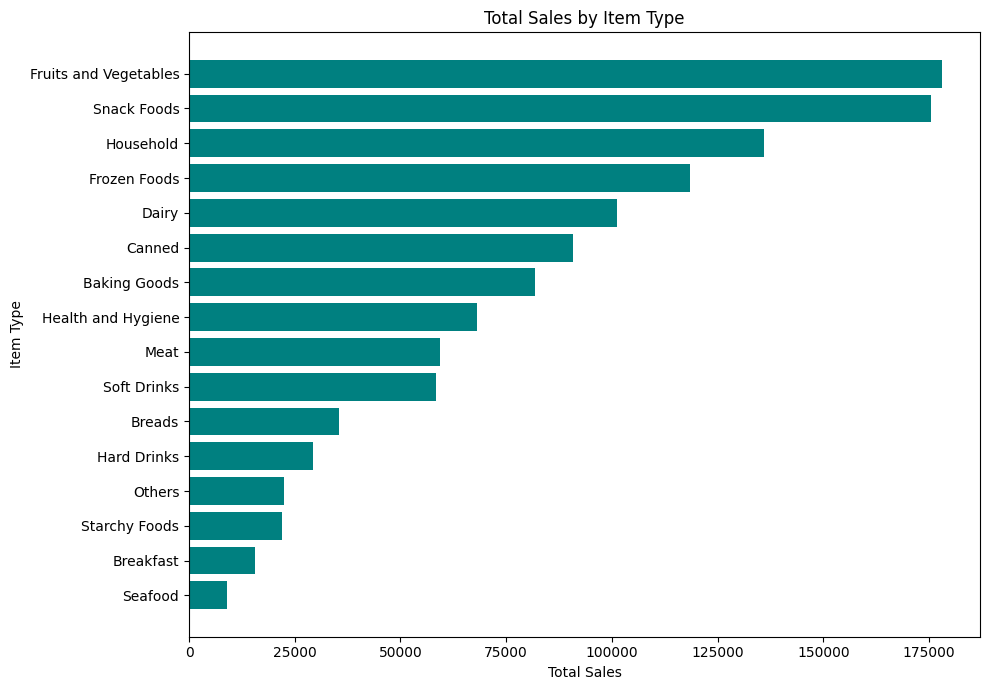

In [89]:
item_check = item_check.sort_values('sum')
plt.figure(figsize=(10,7))
plt.barh(item_check.index, item_check['sum'], color='teal')
plt.xlabel('Total Sales')
plt.ylabel('Item Type')
plt.title('Total Sales by Item Type')
plt.tight_layout()
plt.show()

**Question 3 conclusion**

The best-selling products are Fruits and Vegetables, Snack Foods and Household in every outlet type and tier. There is no meaningful difference in the product pattern between outlet types or locations. The first two lead mainly because they have more listings; Household is strong on both total and per-product sales.

### **Category 2: Product-Level Analysis**

#### **Question 4: Which product type sells the most overall?**
This question is answered by the item type table and chart above.

- **Fruits and Vegetables** has the highest total sales (~RM178K), narrowly ahead of **Snack Foods** (~RM175K).
- Both lead because they have the most listings (1,232 and 1,200 rows). Their mean sales per row (~RM145 and ~RM146) are mid-range.
- **Household** is the only item type that is strong on both total sales (3rd, ~RM136K) and mean per row (highest, ~RM149).

**Answer:** Fruits and Vegetables sells the most in total, but mainly because of how many products it includes.

#### **Question 5: Do customers prefer Low Fat or Regular products?**
This dataset shows what is stocked and sold, not what customers choose, so the question is interpreted as: *what share of sales comes from Low Fat vs Regular products?*

**Step 1: basic comparison** using `sum`, `mean` and `count`.

In [90]:
df.groupby('Item Fat Content')['Sales'].agg(['sum', 'mean', 'count'])

,sum,mean,count
Item Fat Content,,,
Low Fat,776319.6784,140.714098,5517
Regular,425361.8024,141.504259,3006


**First result:** Low Fat accounts for ~65% of total sales and ~65% of rows (5,517 vs 3,006), while the mean per row is almost identical (RM140.7 vs RM141.5). Before trusting this, check the data.

**Step 2: check the data before trusting the result.** A cross-tabulation (`crosstab`) counts the rows for each combination of item type and fat content.

In [91]:
pd.crosstab(df['Item Type'], df['Item Fat Content'])

Item Fat Content,Low Fat,Regular
Item Type,,
Baking Goods,329,319
Breads,140,111
Breakfast,41,69
Canned,341,308
Dairy,418,264
Frozen Foods,450,406
Fruits and Vegetables,630,602
Hard Drinks,214,0
Health and Hygiene,520,0


**Finding:** Household (910 rows), Health and Hygiene (520), Others (169) and Hard Drinks (214) have **zero** Regular rows. Cleaning products and toiletries cannot have a fat content, so the "Low Fat" label on them is a default value, not real information. It inflates the Low Fat count.

**Step 3: fair comparison, food only.** Household, Health and Hygiene and Others (non-food) are excluded. Hard Drinks was kept because it is a consumable product; this is a judgment call and affects only 214 rows.

In [92]:
non_food = ['Household', 'Health and Hygiene', 'Others']
df_food = df[~df['Item Type'].isin(non_food)]

df_food.groupby('Item Fat Content')['Sales'].agg(['sum', 'mean', 'count'])


,sum,mean,count
Item Fat Content,,,
Low Fat,549865.4226,140.343395,3918
Regular,425361.8024,141.504259,3006


**Insight**

| | Low Fat | Regular | Low Fat share |
|---|---|---|---|
| All items: rows | 5,517 | 3,006 | ~65% |
| Food only: rows | 3,918 | 3,006 | ~57% |
| Food only: sum of sales | 549,865 | 425,362 | ~56% |
| Food only: mean per row | 140.3 | 141.5 | |

- Removing the non-food items drops Low Fat's share from ~65% to ~56%. About nine percentage points of its apparent lead came from the default label.
- The mean per row is almost the same for both (RM140 vs RM141).

**Why compare shares instead of raw totals?** Removing 1,599 rows shrinks every total, so before-and-after raw totals are not comparable. A percentage share stays meaningful when the size of the data changes.

**Question 5 conclusion**

Low Fat still produces more total sales (~56% of food sales), but because **more Low Fat products are listed** (3,918 vs 3,006 rows), not because each Low Fat product sells more. Per-product sales are almost equal.

> **Caveat:** the data cannot separate "customers prefer Low Fat" from "outlets stock more Low Fat".

### **Category 3: Driver & Root-Cause Analysis**
These questions ask *why*, not just *what*, so we use **correlation**, **scatter plots** and **stratification** (testing the same question inside each subgroup).

#### **Question 6: Does higher visibility lead to higher sales, or does it depend on product type?**

**Step 1: handle `Item Visibility = 0`.** A product that is on sale cannot have zero visibility, so a zero most likely means "not recorded". We do not fill these with an estimate, because visibility is the variable being tested and estimated values would create the very data we want to examine. Instead, they are excluded **for this question only**.

In [93]:
# Step 1: Count rows where Item Visibility = 0
(df['Item Visibility'] == 0).sum()

np.int64(526)

In [94]:
df_vis = df[df['Item Visibility'] > 0]
print(len(df), len(df_vis))

8523 7997


526 rows (~6%) have zero visibility. They are removed into a separate DataFrame `df_vis`, leaving **7,997 rows**. The original `df` is unchanged for the other questions. This is an **assumption**: zeros are treated as unrecorded values.

**Step 2: correlation.** The correlation coefficient *r* runs from -1 to +1:
- close to **+1**: visibility rises, sales rise
- close to **0**: no linear relationship
- close to **-1**: visibility rises, sales fall

In [95]:
# Step 2: Correlation
df_vis['Item Visibility'].corr(df_vis['Sales'])

np.float64(-0.0056997518783149246)

**Result:** r = -0.006, essentially zero. Knowing a product's visibility gives no help in predicting its sales.

**Step 3: scatter plot** to see the relationship directly. `alpha` makes points transparent so dense areas look darker.

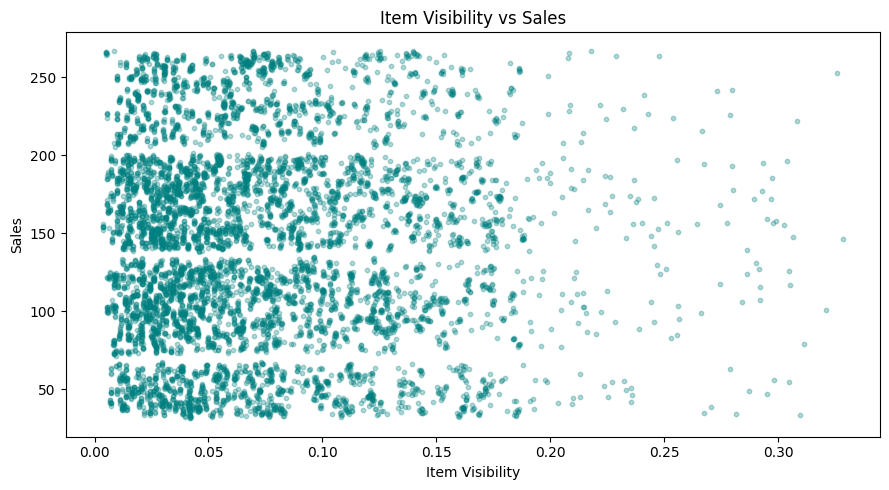

In [96]:
# Step 3: Scatter plot

plt.figure(figsize=(9,5))
plt.scatter(df_vis['Item Visibility'], df_vis['Sales'], alpha=0.3, s=10, color='teal')
plt.xlabel('Item Visibility')
plt.ylabel('Sales')
plt.title('Item Visibility vs Sales')
plt.tight_layout()
plt.show()

**What the chart shows**
- The points are spread evenly with no upward or downward tilt, matching r ~ 0.
- Sales fall in horizontal bands, which suggests sales are driven by something that comes in tiers (possibly product price). The dataset has no price column, so this cannot be tested.
- Above a visibility of ~0.2 there are few points, so evidence for very high visibility is limited.

**Step 4: "or does it depend on product type?"** Stratification: compute the correlation inside each item type. (The pandas `DeprecationWarning` shown below is harmless; it only announces a change in a future pandas version.)

In [97]:
# Step 4: Correlation within each item type

corr_by_type = df_vis.groupby('Item Type').apply(
    lambda g: g['Item Visibility'].corr(g['Sales'])
).sort_values()
print(corr_by_type) 

Item Type
Breakfast               -0.240547
Breads                  -0.084964
Frozen Foods            -0.069387
Baking Goods            -0.061277
Starchy Foods           -0.061162
Dairy                   -0.050324
Meat                    -0.036568
Fruits and Vegetables   -0.031903
Health and Hygiene      -0.015498
Snack Foods              0.004284
Household                0.015078
Canned                   0.062462
Hard Drinks              0.069566
Others                   0.119325
Seafood                  0.185943
Soft Drinks              0.194255
dtype: float64


C:\Users\Adeei\AppData\Local\Temp\ipykernel_6700\3820864034.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr_by_type = df_vis.groupby('Item Type').apply(


**Insight**
- Most item types are close to zero (between about -0.09 and +0.12).
- **Breakfast (-0.24)** and **Seafood (+0.19)** stand out, but they are the smallest categories (110 and 64 rows in total, see the Question 3 table). Correlations from small samples are easily produced by chance, and with 16 groups tested, a few will look unusual by luck alone.
- **Soft Drinks (+0.19)** is the only sizeable category (445 rows) with a noticeable correlation, but it is weak: r² is about 4%, so visibility explains only a small fraction of its sales variation.

**Question 6 conclusion**

Visibility is not associated with sales overall (r = -0.006), and no item type shows a strong relationship. Only Soft Drinks shows a weak positive effect.

> **Caveats:** (1) the 526 zero-visibility rows were excluded on an assumption; (2) this is a one-time snapshot, so it shows association, not whether *changing* visibility would change sales. Testing that would need an experiment.

#### **Question 7: Which products underperform, and why?**

**Step 0: define "underperform".** The dataset has no such label, so we must define it, and the definition is an analytical decision: a product underperforms if its sales are in the **bottom 25% within its own outlet**. Comparing within an outlet keeps the comparison fair.

**Step 1: flag underperforming products.** `quantile(0.25)` finds the sales value below which 25% of an outlet's rows fall. `transform` computes it per outlet and places it back on every row of that outlet.

In [98]:
# Step 1: Flag underperforming products (bottom 25% of sales within each outlet)
df['outlet_q25'] = df.groupby('Outlet Identifier')['Sales'].transform(lambda s: s.quantile(0.25))
df['underperform'] = df['Sales'] < df['outlet_q25']
df['underperform'].mean()

np.float64(0.2502639915522703)

The share flagged is 0.2503, i.e. 25%, as defined. Since every outlet has exactly 25% flagged by design, the question is not *which outlet has more underperformers* but *what kind of product tends to underperform*.

**Step 2: test three suspects** (rating, fat content, item type). If a factor made no difference, the share of underperformers would be ~25% in every group.

In [99]:
# Step 2: Test three suspects: rating, fat content, item type
print(df.groupby('underperform')['Rating'].agg(['mean', 'median']))
print(df.groupby('Item Fat Content')['underperform'].mean())
print(df.groupby('Item Type')['underperform'].mean().sort_values())

                  mean  median
underperform                  
False         3.966182     4.0
True          3.964885     4.0
Item Fat Content
Low Fat    0.245242
Regular    0.259481
Name: underperform, dtype: float64
Item Type
Household                0.184615
Seafood                  0.187500
Snack Foods              0.190833
Breakfast                0.218182
Meat                     0.221176
Fruits and Vegetables    0.227273
Health and Hygiene       0.238462
Hard Drinks              0.242991
Breads                   0.262948
Others                   0.272189
Starchy Foods            0.283784
Frozen Foods             0.287383
Canned                   0.291217
Dairy                    0.293255
Soft Drinks              0.325843
Baking Goods             0.333333
Name: underperform, dtype: float64


**Findings**
- **Rating: no effect.** Mean rating is 3.965 for underperformers vs 3.966 for the rest.
- **Fat content: almost no effect.** 24.5% of Low Fat and 25.9% of Regular products underperform.
- **Item type: moderate effect.** The share ranges from 18.5% (Household) to 33.3% (Baking Goods). Baking Goods, Soft Drinks, Dairy, Canned and Frozen Foods lean toward underperforming; Household, Seafood and Snack Foods lean the other way.

**Step 3: are the same products underperforming in every outlet?** For each product sold in at least four outlets, `mean` shows the share of its outlets where it underperforms: 0 means never, 1 means always. The cell reports the share of products that are *always* or *never* underperformers.

In [100]:
# Step 3: Are the same products underperforming in every outlet?
item_flag = df.groupby('Item Identifier')['underperform'].agg(['mean', 'count'])
item_flag = item_flag[item_flag['count'] >= 4]   # produk yang dijual di sekurang-kurangnya 4 outlet

((item_flag['mean'] == 0) | (item_flag['mean'] == 1)).mean()

np.float64(0.9686162624821684)

**97%** of products are either underperformers in **all** their outlets or in **none**. Almost no product underperforms in one outlet but not in others.

A supporting check: the variation of sales for the **same product across outlets** versus the overall variation.

In [101]:
within_item_std = df.groupby('Item Identifier')['Sales'].std().mean()
print(within_item_std, df['Sales'].std())


1.1454918740291917 62.27506651219046


**Key finding:** the standard deviation of sales for the same product across outlets is only **1.15**, against **62.3** overall. A product sells almost the same amount in every outlet. In other words, `Sales` behaves like a **fixed attribute of the product** (similar to a price) rather than a result that changes by outlet. This explains why outlet characteristics showed no effect in Questions 1-3 and why rating, visibility and weight show none in Questions 6, 8 and 9.

The ten products with the lowest average sales:

In [102]:
bottom10 = df.groupby(['Item Identifier', 'Item Type'])['Sales'].mean().sort_values().head(10)
print(bottom10)


Item Identifier  Item Type   
DRK12            Soft Drinks     32.315000
FDG40            Frozen Foods    32.980800
FDX59            Breads          33.655800
NCR42            Household       33.690000
FDV28            Frozen Foods    33.998657
FDU21            Snack Foods     34.127229
FDQ47            Breads          34.207400
NCO06            Household       34.272467
FDJ45            Seafood         34.450171
NCE31            Household       34.471600
Name: Sales, dtype: float64


The weakest products (all around RM32-34) come from many item types (Soft Drinks, Frozen Foods, Breads, Household, Snack Foods, Seafood), so no single category is responsible.

**Question 7 conclusion**

Underperformance is **not** explained by rating or fat content. Item type has a moderate influence, but the decisive factor is the **individual product**: a product that underperforms in one outlet underperforms in nearly all outlets. The problem is at product level, not outlet level.

> **Caveat:** `Sales` is a value, not units. Low-value items can look like underperformers even if they sell in large quantities. Do not discontinue products based on this alone; units sold and margin are needed.

#### **Question 8: Is a higher rating associated with higher sales, or is it driven by location?**

**Step 1: correlation.** Pearson r measures a straight-line relationship using the actual values. Spearman compares *rankings* and is better suited to ratings, which take a limited set of values. If both agree, the conclusion is more reliable.

In [103]:
# Step 1: Correlation
print(df['Rating'].corr(df['Sales']))
print(df['Rating'].corr(df['Sales'], method='spearman'))


0.011329313267942356
-0.0004465348558665968


**Result:** Pearson 0.011 and Spearman -0.0004. Both are essentially zero.

**Step 2: average sales per rating band.** `pd.cut` groups ratings into bands. If higher ratings helped sales, the averages should rise from left to right.

In [104]:
# Step 2: Average sales by rating band
df['rating_band'] = pd.cut(df['Rating'],
                           bins=[0, 3, 4, 4.99, 5],
                           labels=['<=3', '3-4', '4-4.99', '5'],
                           include_lowest=True)

df.groupby('rating_band', observed=True)['Sales'].agg(['mean', 'count'])

,mean,count
rating_band,,
<=3,138.990308,617
3-4,141.970952,4734
4-4.99,140.091596,2745
5,138.834994,427


**Result:** the averages are flat (~RM139-142). Products rated 5 sell the same as products rated 3 or below.

**Step 3: "or is it driven by location?"** Stratification: if location were hiding a relationship, the correlation would differ or vanish inside each tier.

In [105]:
#Step 3: Bahagian "atau sebab lokasi" (teknik baru: stratification)
df.groupby('Outlet Location Type').apply(lambda g: g['Rating'].corr(g['Sales']))

C:\Users\Adeei\AppData\Local\Temp\ipykernel_6700\4030248703.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby('Outlet Location Type').apply(lambda g: g['Rating'].corr(g['Sales']))


Outlet Location Type
Tier 1    0.010144
Tier 2    0.016649
Tier 3    0.007689
dtype: float64

**Result:** the correlation is ~0.01 in all three tiers. Location is **not** hiding a relationship; there is no relationship in any tier.

**Step 4: the shape of the rating itself.**

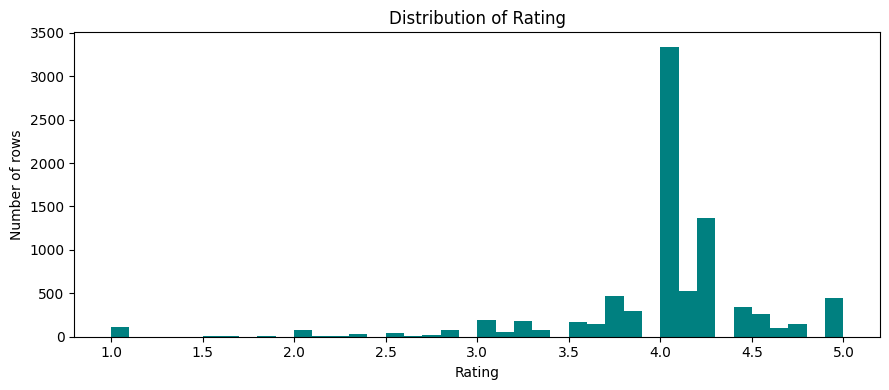

Rating
4.0    3339
4.3     694
4.2     673
4.1     524
5.0     427
Name: count, dtype: int64

In [106]:
# Step 4: Distribution of Rating
plt.figure(figsize=(9, 4))
plt.hist(df['Rating'], bins=40, color='teal')
plt.xlabel('Rating')
plt.ylabel('Number of rows')
plt.title('Distribution of Rating')
plt.tight_layout()
plt.show()

df['Rating'].value_counts().head(5)

**What the distribution shows:** there is a very tall spike at **exactly 4.0** (3,339 rows, ~39% of all data), with smaller bumps at round numbers (1.0, 2.0, 3.0, 5.0). Genuine customer ratings rarely pile up on one number like this. This suggests many ratings may be **default or rounded values** rather than real feedback. This is an interpretation; the dataset does not document how ratings were collected.

**Question 8 conclusion**

There is no relationship between rating and sales (r ~ 0.01), and location does not change that. The rating distribution also suggests the rating column may not be a genuine measure of customer satisfaction.

> **Caveat:** this does not mean ratings are unimportant for the business; it means the ratings in this dataset do not explain sales.

#### **Question 9: Does product weight influence sales, or is it driven by product type?**

**Step 0: investigate the missing weights.** Before analyzing weight, revisit the 1,463 missing values from the cleaning stage. Two questions: *which outlets* are they missing from, and *does a product have the same weight in every outlet*? (`raw` is a fresh copy of the original file, before any filling.)

In [107]:
#Step 0: Siasat 1,463 row yang hilang tu
raw = pd.read_csv('blinkit_data.csv')
print(raw[raw['Item Weight'].isna()].groupby('Outlet Identifier').size())
print(raw.groupby('Item Identifier')['Item Weight'].nunique().value_counts())

Outlet Identifier
OUT019    528
OUT027    935
dtype: int64
Item Weight
1    1555
0       4
Name: count, dtype: int64


**Findings**
- **All** the missing weights (528 + 935 = 1,463) come from just **two outlets**, OUT019 and OUT027, which never recorded weight. The data is missing systematically, not at random.
- Every product (1,555 of them) has **exactly one weight** across all outlets; only 4 products have no weight recorded anywhere.

So a missing weight can be recovered from the same product in another outlet. This is better than the mean, which gave all 1,463 rows the same invented value (~12.86).

**Better fill:** copy the product's weight from other outlets. Only values that are still missing are filled.

In [108]:
item_weight = raw.groupby('Item Identifier')['Item Weight'].mean()
df['Item Weight'] = raw['Item Weight'].fillna(raw['Item Identifier'].map(item_weight))
df['Item Weight'].isna().sum()

np.int64(4)

Only **4 rows** remain missing (products with no weight in any outlet). They are left blank instead of invented; the correlation calculations ignore them automatically. This replaces the earlier mean-filled values.

**Step 1: correlation** (Pearson and Spearman).

In [109]:
#Step 1: Correlation
print(df['Item Weight'].corr(df['Sales']))
print(df['Item Weight'].corr(df['Sales'], method='spearman'))

0.025974751598188683
0.029523106976790555


**Result:** 0.026 and 0.030. Positive, but very close to zero.

**Step 2: average sales per weight band.**

In [110]:
# Step 2: Average sales by weight band
df['weight_band'] = pd.cut(df['Item Weight'], bins=[0, 8, 12, 16, 25])
df.groupby('weight_band', observed=True)['Sales'].agg(['mean', 'count'])

,mean,count
weight_band,,
"(0, 8]",139.154671,1691
"(8, 12]",140.062200,2152
"(12, 16]",140.395335,2099
"(16, 25]",143.519653,2577


**Result:** average sales rise slightly from ~RM139 (lightest products) to ~RM144 (heaviest), a difference of about RM4.4 on sales that vary by ~RM62.

**Step 3: "or is it product type?"** 
(a) Do item types that weigh more also sell more? 
(b) Stratification: is the weight-sales correlation present *inside* each item type?
Step 3: Bahagian "atau sebab jenis produk"


In [111]:
# (a) Do item types differ in weight and sales?
df.groupby('Item Type')[['Item Weight', 'Sales']].mean().round(1).sort_values('Sales')

,Item Weight,Sales
Item Type,,
Baking Goods,12.3,126.4
Health and Hygiene,13.1,130.8
Soft Drinks,11.9,131.5
Others,14.0,132.9
Hard Drinks,11.5,137.1
Frozen Foods,12.8,138.5
Canned,12.4,139.8
Meat,12.8,139.9
Breads,11.3,141.0


**(a) Result:** no pattern. For example, "Others" is the heaviest type (14.0) but sells only ~RM133, while Breads is among the lightest (11.3) and sells ~RM141. If weight led to higher sales through item type, heavier types would sell more.

In [112]:
# (b) Stratification: weight-sales correlation within each item type
df.groupby('Item Type').apply(lambda g: g['Item Weight'].corr(g['Sales'])).sort_values()

C:\Users\Adeei\AppData\Local\Temp\ipykernel_6700\1301511230.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby('Item Type').apply(lambda g: g['Item Weight'].corr(g['Sales'])).sort_values()


Item Type
Hard Drinks             -0.086389
Breads                  -0.084767
Household               -0.065514
Others                  -0.059234
Seafood                 -0.038915
Fruits and Vegetables   -0.036526
Frozen Foods            -0.034783
Starchy Foods           -0.020298
Health and Hygiene      -0.003728
Canned                   0.018208
Soft Drinks              0.020459
Meat                     0.030942
Breakfast                0.066539
Snack Foods              0.087650
Dairy                    0.131466
Baking Goods             0.169948
dtype: float64

**(b) Result:** the correlations run from about -0.09 to +0.17 and **change sign** between item types. If weight truly influenced sales, the direction would be the same everywhere. Mixed signs are a typical sign of noise. Only Baking Goods (+0.17) and Dairy (+0.13) are somewhat positive, and both are weak.

**Step 4: how much does weight explain?** `r²` is the share of the variation in sales explained by weight.

In [113]:
#Step 4: How much of the variation in sales does weight explain?
r = df['Item Weight'].corr(df['Sales'])
print(r ** 2)

0.0006746877205876055


Weight explains about **0.07%** of the variation in sales. With 8,500+ rows even a tiny correlation can be statistically detectable, so the **size of the effect** (r²) matters more than whether an effect can be detected.

For comparison, how much does **item type** explain? The cell computes the share of variation removed by replacing each row's sales with its item type's average.

In [114]:
# How much of the variation in sales does item type explain?type_means = df.groupby('Item Type')['Sales'].transform('mean')
1 - ((df['Sales'] - type_means) ** 2).sum() / ((df['Sales'] - df['Sales'].mean()) ** 2).sum()

NameError: name 'type_means' is not defined

Item type explains about **1.25%** of the variation in sales, roughly 18 times more than weight, but still very little.

**Question 9 conclusion**

Product weight is not meaningfully related to sales (r = 0.026, r² = 0.07%). The slight relationship that exists is not explained by product type, and inside each item type its direction is inconsistent. Item type itself explains only ~1.25% of sales variation. Most of the variation comes from individual products, which agrees with Question 7.

## **5. Summary**

### Answers to the nine questions
| # | Question | Answer |
|---|---|---|
| 1 | Does outlet establishment year affect sales? | No. Average sales are ~RM139-143 for every year |
| 2 | Which outlet and location sell the most? | OUT035 and Tier 3 have the highest totals, but only because they list more products; per-product sales are the same |
| 3 | What sells best in each outlet type and location? | Fruits and Vegetables, Snack Foods and Household everywhere; the first two lead because of many listings |
| 4 | Which product type sells the most overall? | Fruits and Vegetables (total), driven by the number of products |
| 5 | Low Fat or Regular? | Low Fat ~56% of food sales, but per-product sales are equal |
| 6 | Does visibility drive sales? | No (r = -0.006); only Soft Drinks shows a weak effect |
| 7 | Why do products underperform? | A product-level trait (97% consistent across outlets); not rating or fat content |
| 8 | Does rating drive sales? | No (r ~ 0.01), and location does not change that |
| 9 | Does weight drive sales? | No (r² = 0.07%); item type explains only ~1.25% |

### Main finding
**Sales in this dataset are almost entirely determined by the product itself.** The same product sells nearly the same amount in every outlet (standard deviation 1.15 vs 62.3 overall). None of the outlet or product characteristics tested (age, type, tier, visibility, rating, weight, fat content) explains sales to a meaningful degree.

### Data quality issues found and how they were handled
| Issue | Handling |
|---|---|
| `Item Fat Content` had 5 labels for 2 categories | Standardized to Low Fat and Regular |
| `Outlet Size` was inconsistent for OUT010, OUT017, OUT045 | Set to each outlet's most frequent size; treated as unreliable and not used for conclusions |
| `Item Weight` missing for 1,463 rows (all from OUT019 and OUT027) | Copied from the same product in other outlets; 4 rows left blank |
| `Item Visibility` = 0 for 526 rows | Excluded from Question 6 only, on the assumption they are unrecorded |
| Non-food items labeled "Low Fat" by default | Excluded from the Low Fat vs Regular comparison |
| `Rating` clusters at exactly 4.0 (~39% of rows) | Noted as a limitation; may not reflect real customer feedback |

### Limitations
- **No time dimension:** a one-time snapshot, so trends and seasonality cannot be studied.
- **`Sales` is a value, not units:** high sales may mean high price rather than high demand.
- **No customer data:** the data shows what is stocked and sold, not what customers choose.
- **Association, not causation:** a snapshot cannot show whether changing visibility, rating or range would change sales.
- **Two columns are unreliable:** `Outlet Size` (inconsistent) and `Rating` (clustered).

### Recommendations
1. **Grocery Stores:** they list ~40% fewer products than other outlets. Widening their range could raise total sales, if per-product demand holds (test with a pilot).
2. **Review the product list centrally:** underperformance is a product-level trait, so range decisions can be made for all outlets together. Do not drop products on this evidence alone; check units sold and margin first.
3. **Do not expect visibility or rating changes alone to move sales** based on this data. Test with a controlled experiment (for example, compare shelf placement across similar outlets).
4. **Collect better data:** sale dates, units sold, price and margin, and documented rating collection. These would allow the questions this dataset could not answer.

### Key concepts used in this project
- **sum / mean / count:** total, typical value per row, number of rows. A high sum can simply mean more rows.
- **Confounding variable:** a hidden factor that creates or hides a relationship (here, the number of rows or products behind a total).
- **Correlation (r):** strength of a linear relationship from -1 to +1. Pearson uses values; Spearman uses rankings.
- **r-squared:** the share of variation in one variable explained by another. It tells how *meaningful* a relationship is.
- **Stratification:** repeating the same test inside each subgroup (for example each tier or item type) to check for hidden effects.
- **Imputation:** filling in missing values. The best method depends on *why* the values are missing.
- **Quantile:** a cut-off such as the 25th percentile, used here to define "underperform".